# amyloid-$B$-ratios-plotter-holdout
9.10.25

Want to generate boxplots to confirm the fidings in the SMTG *Sci. Data* publication, wherein the two
canonical Amyloid-$B$ peptides are way higher abundance in ADAD samples compared to sporadic to
HCF-low/high. The difference between this and the earlier version of this analysis is that now we're 
doing it after a 20% MNAR holdout. Would be nice to confirm that we can still recapitulate the expecation, 
after imputing a significant portion of the quants. 

We need to confirm that we actually have a substantial fraction of missing values in the Amyloid-B peptides 
themselves...otherwise, we might want to redo this analysis with just an MCAR holdout. 

In [65]:
import pandas as pd
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

# plotting templates
sns.set(context="talk", style="ticks") 
pal = sns.color_palette("tab10")

#### Configs

In [66]:
report_path="../quant-reports/SMTG-MCAR-holdout-nettle-quants-report.csv"
#report_path="../plugin-reports/SMTG-MCAR-holdout-knn-imputed.csv"
meta_path="../data/smtg-metadata.csv"

#### Functions 

In [67]:
def get_zscores(mat):
    """
    Gets the z-score of an input matrix. Doing this by hand because I 
    don't totally understand scipy's axis feature w.r.t. the zscore
    function. 

    Parameters
    ----------
    mat : np.ndarray OR pandas.DataFrame, 
        The input array
        
    Returns
    ----------
    mat_scores : np.ndarray OR pandas.DataFrame, 
        The z-score transformed version of the input matrix
    """
    curr_mean = np.nanmean(mat)
    curr_std = np.nanstd(mat)
    mat_scores = (mat - curr_mean) / curr_std
    return mat_scores

#### Read in the SMTG metadata file
The TZRXX samples are from SMTG. The HADTXX samples are brain QC. 

In [68]:
smtg_metadata = pd.read_csv(meta_path)
#smtg_metadata.head(3)

#### Read in and pre-process the Nettle Skyline report
Need to remove the QC and process control sample columns. 

In [69]:
todrop = ["Peptide Modified Sequence", "Precursor Charge"]
#nettle_mat = pd.read_csv(report_path, index_col=0)
nettle_mat = pd.read_csv(report_path)
nettle_mat = nettle_mat[nettle_mat["Protein Name"] != "Decoys"]

nettle_mat.index = nettle_mat["Peptide Modified Sequence"]
nettle_mat = nettle_mat.drop(columns=todrop)

print(nettle_mat.shape)

(118348, 63)


#### Isolate the protein IDs

In [70]:
prot_ids_nettle = []
for x in list(nettle_mat["Protein Name"]):
    try: 
        y = x.split("|")[2]
        z = y.split("_")[0]
    except IndexError: 
        z = x
    prot_ids_nettle.append(z)

nettle_mat = nettle_mat.drop(columns=["Protein Name"])

#### What is the missingness fraction? 

In [71]:
nan_count = np.count_nonzero(np.isnan(nettle_mat))
np.around(nan_count / nettle_mat.size, 2)

0.16

#### Isolate just the sample ID from the column names 

In [72]:
new_col_ids = [x.split(" ")[0] for x in nettle_mat.columns]
nettle_mat.columns = new_col_ids

new_colnames = [x.split("-")[-1] for x in nettle_mat.columns]
nettle_mat.columns = new_colnames

#### Handle the missing values (?) 

In [73]:
#nettle_mat[np.isnan(nettle_mat)] = 1e-6
nettle_mat[np.isinf(nettle_mat)] = np.nan
nettle_mat[nettle_mat == 0] = np.nan

#### Log the quants

In [74]:
#nettle_mat = np.log(nettle_mat)

#### Get the sample IDs corresponding to each condition 

In [75]:
meta_add = smtg_metadata[smtg_metadata["Condition"] == "Autosomal Dominant ADD"]
add_sample_ids = list(meta_add["Sample Label"])

meta_sporadic = smtg_metadata[smtg_metadata["Condition"] == "Sporadic ADD"]
sporadic_sample_ids = list(meta_sporadic["Sample Label"])

meta_hcf_low = smtg_metadata[smtg_metadata["Condition"] == "HCF/Low ADNC"]
hcf_low_sample_ids = list(meta_hcf_low["Sample Label"])

meta_hcf_high = smtg_metadata[smtg_metadata["Condition"] == "HCF/High ADNC"]
hcf_high_sample_ids = list(meta_hcf_high["Sample Label"])

print(f"Autosomal Dominant ADD: {len(add_sample_ids)}")
print(f"Sporadic ADD: {len(sporadic_sample_ids)}")
print(f"HCF/Low ADNC: {len(hcf_low_sample_ids)}")
print(f"HCF/High ADNC: {len(hcf_high_sample_ids)}")

Autosomal Dominant ADD: 24
Sporadic ADD: 18
HCF/Low ADNC: 9
HCF/High ADNC: 11


#### Isolate the quants matrices for each of the four conditions

In [76]:
add_nettle_mat = nettle_mat[add_sample_ids]
sporadic_nettle_mat = nettle_mat[sporadic_sample_ids]
hcf_low_nettle_mat = nettle_mat[hcf_low_sample_ids]
hcf_high_nettle_mat = nettle_mat[hcf_high_sample_ids]

add_nettle_mat = add_nettle_mat.drop_duplicates(keep="first")
sporadic_nettle_mat = sporadic_nettle_mat.drop_duplicates(keep="first")
hcf_low_nettle_mat = hcf_low_nettle_mat.drop_duplicates(keep="first")
hcf_high_nettle_mat = hcf_high_nettle_mat.drop_duplicates(keep="first")

# add_nettle = np.array(add_nettle_mat)
# sporadic_nettle = np.array(sporadic_nettle_mat)
# hcf_low_nettle = np.array(hcf_low_nettle_mat)
# hcf_high_nettle = np.array(hcf_high_nettle_mat)

#### Get the z-scores? 
For each of the four sample matrices separately. I think this is the best thing to do -- these are 
essentially batches, and you'd want to analyze the batches separately. 

In [77]:
add_nettle_zscores = get_zscores(add_nettle_mat)
sporadic_nettle_zscores = get_zscores(sporadic_nettle_mat)
hcf_low_nettle_zscores = get_zscores(hcf_low_nettle_mat)
hcf_high_nettle_zscores = get_zscores(hcf_high_nettle_mat)

#### Search for the LVF specific Amyloid-$B$ peptide 
LVFFAEDVGSNK should be high in ADAD. 

In [78]:
lvf_add_arr = np.array(add_nettle_zscores.loc["LVFFAEDVGSNK"])
lvf_sporadic_arr = np.array(sporadic_nettle_zscores.loc["LVFFAEDVGSNK"])
lvf_hcf_low_arr = np.array(hcf_low_nettle_zscores.loc["LVFFAEDVGSNK"])
lvf_hcf_high_arr = np.array(hcf_high_nettle_zscores.loc["LVFFAEDVGSNK"])

npad_sporadic = len(lvf_add_arr) - len(lvf_sporadic_arr)
pad_sporadic = np.zeros(npad_sporadic)
pad_sporadic[:] = np.nan
lvf_sporadic_arr = np.concatenate((lvf_sporadic_arr, pad_sporadic))

npad_hcf_low = len(lvf_add_arr) - len(lvf_hcf_low_arr)
pad_hcf_low = np.zeros(npad_hcf_low)
pad_hcf_low[:] = np.nan
lvf_hcf_low_arr = np.concatenate((lvf_hcf_low_arr, pad_hcf_low))

npad_hcf_high = len(lvf_add_arr) - len(lvf_hcf_high_arr)
pad_hcf_high = np.zeros(npad_hcf_high)
pad_hcf_high[:] = np.nan
lvf_hcf_high_arr = np.concatenate((lvf_hcf_high_arr, pad_hcf_high))

#### Search for the HDS Amyloid-$B$ peptide 

In [79]:
hds_add_arr = np.array(add_nettle_zscores.loc["HDSGYEVHHQK"])
hds_sporadic_arr = np.array(sporadic_nettle_zscores.loc["HDSGYEVHHQK"])
hds_hcf_low_arr = np.array(hcf_low_nettle_zscores.loc["HDSGYEVHHQK"])
hds_hcf_high_arr = np.array(hcf_high_nettle_zscores.loc["HDSGYEVHHQK"])

npad_sporadic = len(hds_add_arr) - len(hds_sporadic_arr)
pad_sporadic = np.zeros(npad_sporadic)
pad_sporadic[:] = np.nan
hds_sporadic_arr = np.concatenate((hds_sporadic_arr, pad_sporadic))

npad_hcf_low = len(hds_add_arr) - len(hds_hcf_low_arr)
pad_hcf_low = np.zeros(npad_hcf_low)
pad_hcf_low[:] = np.nan
hds_hcf_low_arr = np.concatenate((hds_hcf_low_arr, pad_hcf_low))

npad_hcf_high = len(hds_add_arr) - len(hds_hcf_high_arr)
pad_hcf_high = np.zeros(npad_hcf_high)
pad_hcf_high[:] = np.nan
hds_hcf_high_arr = np.concatenate((hds_hcf_high_arr, pad_hcf_high))

#### Create dataframes to hold the z-scores for the two peptides

In [80]:
# For LVF
lvf_df = pd.DataFrame(columns=["ADAD", "Sporadic", "HCF-low", "HCF-high"])
lvf_df["ADAD"] = lvf_add_arr
lvf_df["Sporadic"] = lvf_sporadic_arr
lvf_df["HCF-low"] = lvf_hcf_low_arr
lvf_df["HCF-high"] = lvf_hcf_high_arr
lvf_df_melt = lvf_df.melt()

# For HDS
hds_df = pd.DataFrame(columns=["ADAD", "Sporadic", "HCF-low", "HCF-high"])
hds_df["ADAD"] = hds_add_arr
hds_df["Sporadic"] = hds_sporadic_arr
hds_df["HCF-low"] = hds_hcf_low_arr
hds_df["HCF-high"] = hds_hcf_high_arr
hds_df_melt = hds_df.melt()

#### Plot 

/tmp/ipykernel_2432076/1089716263.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2432076/1089716263.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


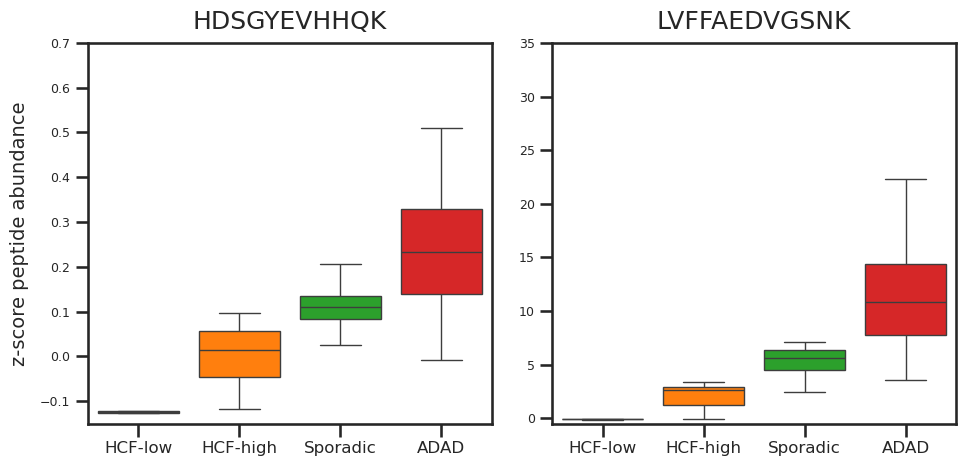

In [81]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10,5))

# FOR HDSGYEVHHQK
sns.boxplot(
    hds_df_melt, x="variable", y="value", 
    order=["HCF-low", "HCF-high", "Sporadic", "ADAD"],
    palette="tab10", 
    fliersize=0.0, 
    saturation=1.0,
    ax=ax1,
)
ax1.set_title("HDSGYEVHHQK", pad=10, size=18)
ax1.set_xlabel("")
ax1.set_ylabel("z-score peptide abundance", labelpad=8, size=14)

# FOR LVFFAEDVGSNK
sns.boxplot(
    lvf_df_melt, x="variable", y="value", 
    order=["HCF-low", "HCF-high", "Sporadic", "ADAD"],
    palette="tab10", 
    fliersize=0.0, 
    saturation=1.0,
    ax=ax2,
)
ax2.set_title("LVFFAEDVGSNK", pad=10, size=18)
ax2.set_xlabel("")
ax2.set_ylabel("")

ax2.tick_params(axis="y", which="major", labelsize=8)
ax2.tick_params(axis="x", which="major", labelsize=12)

ax1.set_ylim(-0.15, 0.7)
ax2.set_ylim(-0.5, 35)

ax1.tick_params(axis="y", which="major", labelsize=9)
ax1.tick_params(axis="x", which="major", labelsize=12)

ax2.tick_params(axis="y", which="major", labelsize=9)
ax2.tick_params(axis="x", which="major", labelsize=12)

plt.tight_layout()
#plt.show()
#plt.savefig("../figures/amyloidB-boxplots-kNN-MCAR-holdout.pdf", bbox_inches="tight")
#plt.savefig("../figures/amyloidB-boxplots-lowval-MCAR-holdout.png", dpi=250, bbox_inches="tight")

#### Get the p-values between sample groups for LVF

In [82]:
arr1 = np.array(add_nettle_mat.loc["LVFFAEDVGSNK"])
arr2 = np.array(sporadic_nettle_mat.loc["LVFFAEDVGSNK"])
arr3 = np.array(hcf_high_nettle_mat.loc["LVFFAEDVGSNK"])
arr4 = np.array(hcf_low_nettle_mat.loc["LVFFAEDVGSNK"])

_, ADAD_v_sporadic_pval = ttest_ind(arr1, arr2, nan_policy="omit")
_, ADAD_v_HCF_high_pval = ttest_ind(arr1, arr3, nan_policy="omit")
_, ADAD_v_HCF_low_pval = ttest_ind(arr1, arr4, nan_policy="omit")

print(f"LVF, ADAD vs Sporadic: {np.around(ADAD_v_sporadic_pval, 3)}")
print(f"LVF, ADAD vs HCF-high: {np.around(ADAD_v_HCF_high_pval, 3)}")
print(f"LVF, ADAD vs HCF-low: {np.around(ADAD_v_HCF_low_pval, 3)}")

LVF, ADAD vs Sporadic: 0.0
LVF, ADAD vs HCF-high: 0.0
LVF, ADAD vs HCF-low: 0.0


#### Get the p-values for HDS

In [83]:
arr1 = np.array(add_nettle_mat.loc["HDSGYEVHHQK"])
arr2 = np.array(sporadic_nettle_mat.loc["HDSGYEVHHQK"])
arr3 = np.array(hcf_high_nettle_mat.loc["HDSGYEVHHQK"])
arr4 = np.array(hcf_low_nettle_mat.loc["HDSGYEVHHQK"])

_, ADAD_v_sporadic_pval = ttest_ind(arr1, arr2, nan_policy="omit")
_, ADAD_v_HCF_high_pval = ttest_ind(arr1, arr3, nan_policy="omit")
_, ADAD_v_HCF_low_pval = ttest_ind(arr1, arr4, nan_policy="omit")

print(f"HDS, ADAD vs Sporadic: {np.around(ADAD_v_sporadic_pval, 3)}")
print(f"HDS, ADAD vs HCF-high: {np.around(ADAD_v_HCF_high_pval, 3)}")
print(f"HDS, ADAD vs HCF-low: {np.around(ADAD_v_HCF_low_pval, 3)}")

HDS, ADAD vs Sporadic: 0.006
HDS, ADAD vs HCF-high: 0.0
HDS, ADAD vs HCF-low: 0.0


#### Could we add significance indications to these plots? 

/tmp/ipykernel_2432076/198349952.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2432076/198349952.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


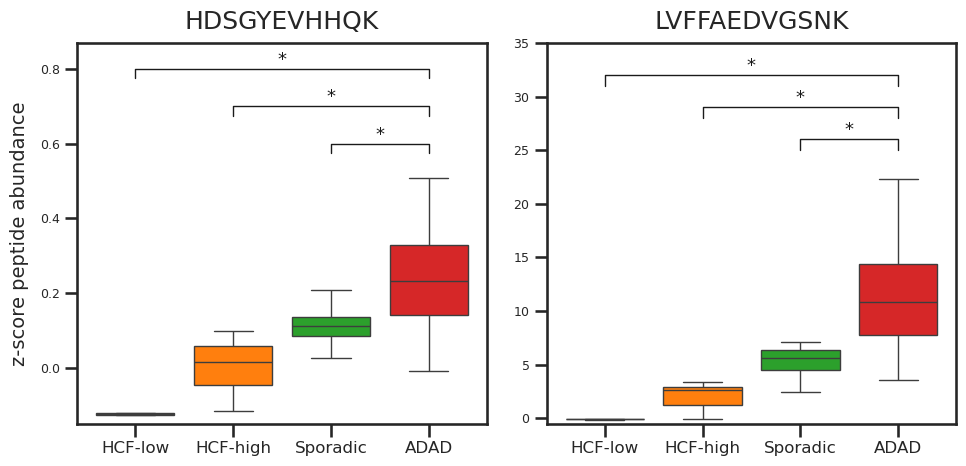

In [97]:
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10,5))

# FOR HDSGYEVHHQK
sns.boxplot(
    hds_df_melt, x="variable", y="value", 
    order=["HCF-low", "HCF-high", "Sporadic", "ADAD"],
    palette="tab10", 
    fliersize=0.0, 
    saturation=1.0,
    ax=ax1,
)
ax1.set_title("HDSGYEVHHQK", pad=10, size=18)
ax1.set_xlabel("")
ax1.set_ylabel("z-score peptide abundance", labelpad=8, size=14)

# FOR LVFFAEDVGSNK
sns.boxplot(
    lvf_df_melt, x="variable", y="value", 
    order=["HCF-low", "HCF-high", "Sporadic", "ADAD"],
    palette="tab10", 
    fliersize=0.0, 
    saturation=1.0,
    ax=ax2,
)
ax2.set_title("LVFFAEDVGSNK", pad=10, size=18)
ax2.set_xlabel("")
ax2.set_ylabel("")

ax2.tick_params(axis="y", which="major", labelsize=8)
ax2.tick_params(axis="x", which="major", labelsize=12)

ax1.set_ylim(-0.15, 0.87)
ax2.set_ylim(-0.5, 35)

ax1.tick_params(axis="y", which="major", labelsize=9)
ax1.tick_params(axis="x", which="major", labelsize=12)

ax2.tick_params(axis="y", which="major", labelsize=9)
ax2.tick_params(axis="x", which="major", labelsize=12)

# Add the significance indicators
ax1.plot([3, 3, 2, 2], [0.575, 0.6, 0.6, 0.575], linewidth=1, color="k")
ax1.text((3 + 2) * 0.5, 0.6, "*", ha='center', va='bottom', c='k', size=13)

ax1.plot([3, 3, 1, 1], [0.675, 0.7, 0.7, 0.675], linewidth=1, color="k")
ax1.text((3 + 1) * 0.5, 0.7, "*", ha='center', va='bottom', c='k', size=13)

ax1.plot([3, 3, 0, 0], [0.775, 0.8, 0.8, 0.775], linewidth=1, color="k")
ax1.text((3 + 0) * 0.5, 0.8, "*", ha='center', va='bottom', c='k', size=13)

ax2.plot([3, 3, 2, 2], [25, 26, 26, 25], linewidth=1, color="k")
ax2.text((3 + 2) * 0.5, 26, "*", ha='center', va='bottom', c='k', size=13)

ax2.plot([3, 3, 1, 1], [28, 29, 29, 28], linewidth=1, color="k")
ax2.text((3 + 1) * 0.5, 29, "*", ha='center', va='bottom', c='k', size=13)

ax2.plot([3, 3, 0, 0], [31, 32, 32, 31], linewidth=1, color="k")
ax2.text((3 + 0) * 0.5, 32, "*", ha='center', va='bottom', c='k', size=13)

plt.tight_layout()
#plt.show()
#plt.savefig("../figures/amyloidB-boxplots-nettle-MCAR-holdout-sig.pdf", bbox_inches="tight")
#plt.savefig("../figures/amyloidB-boxplots-lowval-MCAR-holdout.png", dpi=250, bbox_inches="tight")